In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 36.3 MB/s eta 0:00:00


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("dip-and-cv").project("medicine-identification")
version = project.version(5)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 136.4 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.90
    Uninstalling opencv-python-headless-4.13.0.90:
      Successfully uninstalled opencv-python-headless-4.13.0.90
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Medicine-Identification-5 in yolov8:: 100%|██████████| 5892/5892 [00:00<00:00, 8594.58it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
!rm -f -r /content/Medicine-Identification-3

In [ ]:
from ultralytics import YOLO

# Load a pretrained YOLO26n model
model = YOLO("yolov8n.pt")

# Train the model on the COCO8 dataset for 100 epochs
train_results = model.train(
    data="/content/Medicine-Identification-5/data.yaml",  # Path to dataset configuration file
    epochs=50,  # Number of training epochs
    imgsz=512,  # Image size for training
)

# Evaluate the model's performance on the validation set
metrics = model.val()

# Perform object detection on an image
# results = model("path/to/image.jpg")  # Predict on an image
# results[0].show()  # Display results

# Export the model to ONNX format for deployment
path = model.export(format="onnx")  # Returns the path to the exported model

Ultralytics 8.4.9 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Medicine-Identification-5/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100

Exporting to ONNX opset version 22 is not supported. by 'torch.onnx.export()'. The highest opset version supported is 20. To use a newer opset version, consider 'torch.onnx.export(..., dynamo=True)'. 


ONNX: slimming with onnxslim 0.1.82...
ONNX: export success ✅ 10.3s, saved as '/content/runs/detect/train/weights/best.onnx' (11.7 MB)

Export complete (10.6s)
Results saved to /content/runs/detect/train/weights
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=512 
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=512 data=/content/Medicine-Identification-5/data.yaml  
Visualize:       https://netron.app


In [ ]:
!cp -r /content/runs3 /content/drive/MyDrive/medicine_model

In [ ]:
import roboflow

rf = Roboflow(api_key="YOUR_API_KEY")
project = rf.workspace("dip-and-cv").project("medicne-b8ml7")

#can specify weights_filename, default is "weights/best.pt"
version = project.version('6')
version.deploy("yolov8n", "/content/drive/MyDrive/medicine_model/model1/detect/train/")

loading Roboflow workspace...
loading Roboflow project...
Dependency ultralytics==8.0.196 is required but found version=8.4.9, to fix: `pip install ultralytics==8.0.196`
Would you like to continue with the wrong version of ultralytics? y/n: y
View the status of your deployment at: https://app.roboflow.com/dip-and-cv/medicne-b8ml7/6
Share your model with the world at: https://universe.roboflow.com/dip-and-cv/medicne-b8ml7/model/6


----------------------------------------
** MODEL PERFORMANCE SUMMARY (Epoch 22.0) **
----------------------------------------
Precision (P):    0.7349
Recall (R):       0.7261
mAP@50:           0.7861
mAP@50-95:        0.3982
----------------------------------------

[COPY THIS FOR LATEX TABLE]:
YOLOv8-Text & 512 & 50 & 0.73 & 0.73 & 0.79 & 0.40 \\
----------------------------------------

[INFO] Graph saved as 'training_curves.png'


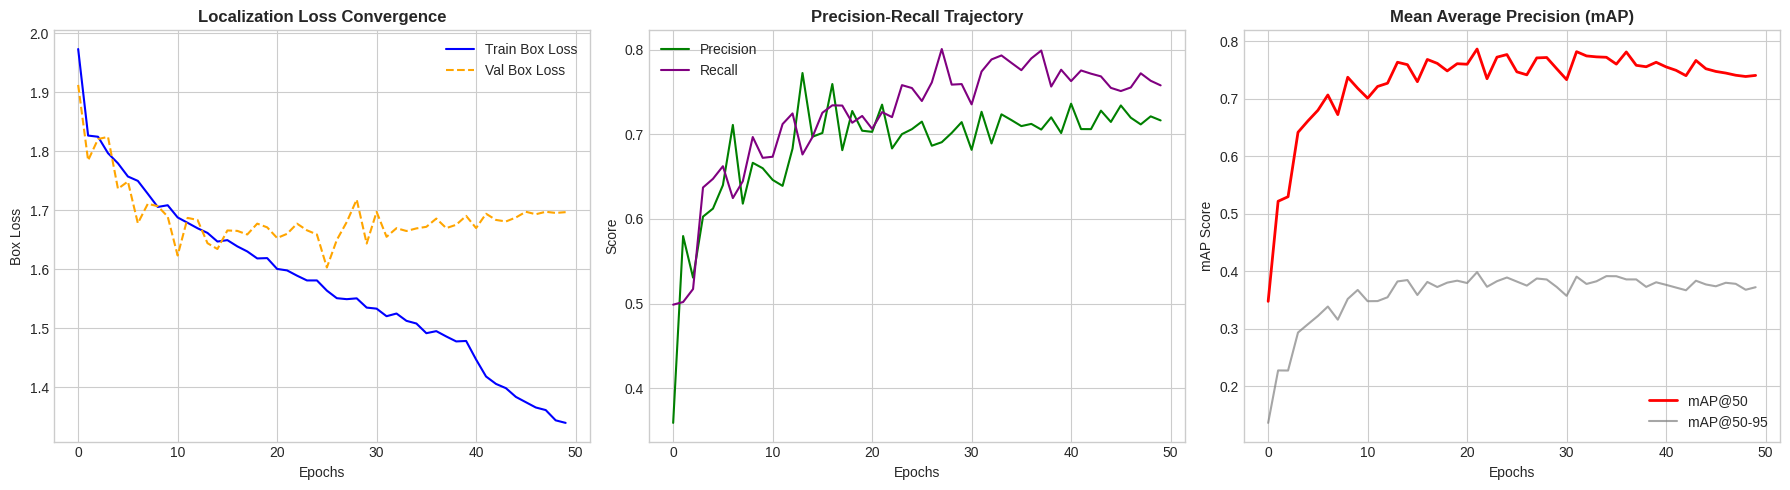

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import yaml

def analyze_yolo_results():
    # 1. Load Data
    try:
        df = pd.read_csv('/content/drive/MyDrive/medicine_model/model1/detect/train/results.csv')
        df.columns = [c.strip() for c in df.columns] # Clean column names

        with open('/content/drive/MyDrive/medicine_model/model1/detect/train/args.yaml', 'r') as f:
            args = yaml.safe_load(f)
    except FileNotFoundError:
        print("Error: Could not find results.csv or args.yaml in current directory.")
        return

    # 2. Extract Key Metrics (Best Epoch)
    best_idx = df['metrics/mAP50(B)'].idxmax()
    best_epoch = df.iloc[best_idx]

    print("-" * 40)
    print(f"** MODEL PERFORMANCE SUMMARY (Epoch {best_epoch['epoch']}) **")
    print("-" * 40)
    print(f"Precision (P):    {best_epoch['metrics/precision(B)']:.4f}")
    print(f"Recall (R):       {best_epoch['metrics/recall(B)']:.4f}")
    print(f"mAP@50:           {best_epoch['metrics/mAP50(B)']:.4f}")
    print(f"mAP@50-95:        {best_epoch['metrics/mAP50-95(B)']:.4f}")
    print("-" * 40)

    # 3. Generate LaTeX Table Row
    print("\n[COPY THIS FOR LATEX TABLE]:")
    print(f"YOLOv8-Text & {args['imgsz']} & {args['epochs']} & "
          f"{best_epoch['metrics/precision(B)']:.2f} & "
          f"{best_epoch['metrics/recall(B)']:.2f} & "
          f"{best_epoch['metrics/mAP50(B)']:.2f} & "
          f"{best_epoch['metrics/mAP50-95(B)']:.2f} \\\\")
    print("-" * 40)

    # 4. Plot Training Curves (Academic Style)
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot A: Loss Convergence
    axes[0].plot(df['train/box_loss'], label='Train Box Loss', color='blue', linewidth=1.5)
    axes[0].plot(df['val/box_loss'], label='Val Box Loss', color='orange', linestyle='--', linewidth=1.5)
    axes[0].set_title('Localization Loss Convergence', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Box Loss')
    axes[0].legend()

    # Plot B: Precision & Recall
    axes[1].plot(df['metrics/precision(B)'], label='Precision', color='green')
    axes[1].plot(df['metrics/recall(B)'], label='Recall', color='purple')
    axes[1].set_title('Precision-Recall Trajectory', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Score')
    axes[1].legend()

    # Plot C: mAP Metrics
    axes[2].plot(df['metrics/mAP50(B)'], label='mAP@50', color='red', linewidth=2)
    axes[2].plot(df['metrics/mAP50-95(B)'], label='mAP@50-95', color='gray', alpha=0.7)
    axes[2].set_title('Mean Average Precision (mAP)', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('mAP Score')
    axes[2].legend()

    plt.tight_layout()
    plt.savefig('training_curves.png', dpi=300)
    print("\n[INFO] Graph saved as 'training_curves.png'")
    plt.show()

if __name__ == "__main__":
    analyze_yolo_results()

In [ ]:
# ====================================================
    # COMPREHENSIVE MEDICINE DATABASE (35 Classes)
    # ====================================================
    # IDs (0-34) must match the 'names' list in your data.yaml
    # Format: {ID: {"brand": "Name", "generic": "Name", "company": "Name"}}
MEDICINE_DB = {
        0: {"brand": "Ace", "generic": "Paracetamol", "company": "Square Pharmaceuticals PLC"},
        1: {"brand": "Alfavir", "generic": "Tenofovir Alafenamide", "company": "Incepta Pharmaceuticals Ltd"},
        2: {"brand": "Atova EZ", "generic": "Atorvastatin + Ezetimibe", "company": "Beximco Pharmaceuticals Ltd"},
        3: {"brand": "Avloclav", "generic": "Amoxicillin + Clavulanic Acid", "company": "ACI Limited"},
        4: {"brand": "AztaCap 4", "generic": "Astaxanthin", "company": "Incepta Pharmaceuticals Ltd"},
        5: {"brand": "Calorate 740", "generic": "Calcium Orotate", "company": "Beximco Pharmaceuticals Ltd"},
        6: {"brand": "Cefaclav", "generic": "Cefuroxime + Clavulanic Acid", "company": "Incepta Pharmaceuticals Ltd"},
        7: {"brand": "Cilvas 5", "generic": "Cilnidipine", "company": "Labaid Pharmaceuticals Ltd"},
        8: {"brand": "Doxiva", "generic": "Doxophylline", "company": "NIPRO JMI Pharma Ltd"},
        9: {"brand": "E-CAP-400", "generic": "Vitamin E", "company": "Drug International Ltd"},
        10: {"brand": "Febustat", "generic": "Febuxostat", "company": "Incepta Pharmaceuticals Ltd"},
        11: {"brand": "Fixocard 50", "generic": "Amlodipine + Atenolol", "company": "Incepta Pharmaceuticals Ltd"},
        12: {"brand": "Fossical-DX", "generic": "Calcium + Vitamin D3", "company": "Aristopharma Ltd"},
        13: {"brand": "Hemofix FZ", "generic": "Ferrous Ascorbate + Folic Acid + Zinc", "company": "Beximco Pharmaceuticals Ltd"},
        14: {"brand": "Linatab M", "generic": "Linagliptin + Metformin", "company": "Incepta Pharmaceuticals Ltd"},
        15: {"brand": "Max Omega", "generic": "Omega-3 Acid Ethyl Esters", "company": "UniMed UniHealth Pharmaceuticals"},
        16: {"brand": "Montene 10", "generic": "Montelukast Sodium", "company": "Square Pharmaceuticals PLC"},
        17: {"brand": "Mycofree-250", "generic": "Terbinafine Hydrochloride", "company": "Drug International Ltd"},
        18: {"brand": "Nabu 750", "generic": "Nabumetone", "company": "ACI Limited"},
        19: {"brand": "Neurobest", "generic": "Vitamin B1+B6+B12", "company": "Renata Limited"},
        20: {"brand": "Ometem", "generic": "Omeprazole", "company": "Team Pharmaceuticals Ltd"},
        21: {"brand": "Omidon", "generic": "Domperidone", "company": "Incepta Pharmaceuticals Ltd"},
        22: {"brand": "Penvik DS", "generic": "Phenoxymethyl Penicillin", "company": "Square Pharmaceuticals PLC"},
        23: {"brand": "Reconil", "generic": "Hydroxychloroquine Sulphate", "company": "Incepta Pharmaceuticals Ltd"},
        24: {"brand": "Solbion", "generic": "Vitamin B1+B6+B12", "company": "Eskayef Pharmaceuticals Ltd"},
        25: {"brand": "TELMIDIP 40", "generic": "Telmisartan + Amlodipine", "company": "Incepta Pharmaceuticals Ltd"},
        26: {"brand": "Toco Soft", "generic": "Tocotrienol + Tocopherol", "company": "Square Pharmaceuticals PLC"},
        27: {"brand": "Triginal MR", "generic": "Trimetazidine Dihydrochloride", "company": "Radiant Pharmaceuticals Ltd"},
        28: {"brand": "Xanra Mups", "generic": "Dexlansoprazole", "company": "OSL Pharma Limited"},
        29: {"brand": "Xidolac", "generic": "Ketorolac Tromethamine", "company": "Beximco Pharmaceuticals Ltd"},
        30: {"brand": "Xorel-20", "generic": "Rabeprazole Sodium", "company": "The IBN SINA Pharmaceutical Industry"},
        31: {"brand": "Zanthin 4", "generic": "Astaxanthin", "company": "Square Pharmaceuticals PLC"},
        32: {"brand": "Zilas", "generic": "Bilastine", "company": "Healthcare Pharmaceuticals Ltd"},
        33: {"brand": "azmasol", "generic": "Salbutamol", "company": "Beximco Pharmaceuticals Ltd"},
        34: {"brand": "superltra", "generic": "Itraconazole", "company": "Eskayef Pharmaceuticals Ltd"}
    }

In [ ]:
!pip install sentence-transformers paddleocr

In [ ]:
pip install -U huggingface-hub sentence-transformers

In [ ]:
!pip install ultralytics paddleocr paddlepaddle huggingface-hub sentence-transformers langchain langchain-community opencv-python-headless fuzzywuzzy python-Levenshtein

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.8/67.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 39.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.1/87.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.7/193.7 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.3/153.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 767.5/767.5 

In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO
# from paddleocr import PaddleOCR
from sentence_transformers import SentenceTransformer, util

# ====================================================
# 1. DATABASE CONFIGURATION
# ====================================================
MEDICINE_DB = {
    0: {"brand": "Ace", "generic": "Paracetamol", "company": "Square Pharmaceuticals PLC"},
    1: {"brand": "Alfavir", "generic": "Tenofovir Alafenamide", "company": "Incepta Pharmaceuticals Ltd"},
    2: {"brand": "Atova EZ", "generic": "Atorvastatin + Ezetimibe", "company": "Beximco Pharmaceuticals Ltd"},
    3: {"brand": "Avloclav", "generic": "Amoxicillin + Clavulanic Acid", "company": "ACI Limited"},
    4: {"brand": "AztaCap 4", "generic": "Astaxanthin", "company": "Incepta Pharmaceuticals Ltd"},
    5: {"brand": "Calorate 740", "generic": "Calcium Orotate", "company": "Beximco Pharmaceuticals Ltd"},
    6: {"brand": "Cefaclav", "generic": "Cefuroxime + Clavulanic Acid", "company": "Incepta Pharmaceuticals Ltd"},
    7: {"brand": "Cilvas 5", "generic": "Cilnidipine", "company": "Labaid Pharmaceuticals Ltd"},
    8: {"brand": "Doxiva", "generic": "Doxophylline", "company": "NIPRO JMI Pharma Ltd"},
    9: {"brand": "E-CAP-400", "generic": "Vitamin E", "company": "Drug International Ltd"},
    10: {"brand": "Febustat", "generic": "Febuxostat", "company": "Incepta Pharmaceuticals Ltd"},
    11: {"brand": "Fixocard 50", "generic": "Amlodipine + Atenolol", "company": "Incepta Pharmaceuticals Ltd"},
    12: {"brand": "Fossical-DX", "generic": "Calcium + Vitamin D3", "company": "Aristopharma Ltd"},
    13: {"brand": "Hemofix FZ", "generic": "Ferrous Ascorbate + Folic Acid + Zinc", "company": "Beximco Pharmaceuticals Ltd"},
    14: {"brand": "Linatab M", "generic": "Linagliptin + Metformin", "company": "Incepta Pharmaceuticals Ltd"},
    15: {"brand": "Max Omega", "generic": "Omega-3 Acid Ethyl Esters", "company": "UniMed UniHealth Pharmaceuticals"},
    16: {"brand": "Montene 10", "generic": "Montelukast Sodium", "company": "Square Pharmaceuticals PLC"},
    17: {"brand": "Mycofree-250", "generic": "Terbinafine Hydrochloride", "company": "Drug International Ltd"},
    18: {"brand": "Nabu 750", "generic": "Nabumetone", "company": "ACI Limited"},
    19: {"brand": "Neurobest", "generic": "Vitamin B1+B6+B12", "company": "Renata Limited"},
    20: {"brand": "Ometem", "generic": "Omeprazole", "company": "Team Pharmaceuticals Ltd"},
    21: {"brand": "Omidon", "generic": "Domperidone", "company": "Incepta Pharmaceuticals Ltd"},
    22: {"brand": "Penvik DS", "generic": "Phenoxymethyl Penicillin", "company": "Square Pharmaceuticals PLC"},
    23: {"brand": "Reconil", "generic": "Hydroxychloroquine Sulphate", "company": "Incepta Pharmaceuticals Ltd"},
    24: {"brand": "Solbion", "generic": "Vitamin B1+B6+B12", "company": "Eskayef Pharmaceuticals Ltd"},
    25: {"brand": "TELMIDIP 40", "generic": "Telmisartan + Amlodipine", "company": "Incepta Pharmaceuticals Ltd"},
    26: {"brand": "Toco Soft", "generic": "Tocotrienol + Tocopherol", "company": "Square Pharmaceuticals PLC"},
    27: {"brand": "Triginal MR", "generic": "Trimetazidine Dihydrochloride", "company": "Radiant Pharmaceuticals Ltd"},
    28: {"brand": "Xanra Mups", "generic": "Dexlansoprazole", "company": "OSL Pharma Limited"},
    29: {"brand": "Xidolac", "generic": "Ketorolac Tromethamine", "company": "Beximco Pharmaceuticals Ltd"},
    30: {"brand": "Xorel-20", "generic": "Rabeprazole Sodium", "company": "The IBN SINA Pharmaceutical Industry"},
    31: {"brand": "Zanthin 4", "generic": "Astaxanthin", "company": "Square Pharmaceuticals PLC"},
    32: {"brand": "Zilas", "generic": "Bilastine", "company": "Healthcare Pharmaceuticals Ltd"},
    33: {"brand": "azmasol", "generic": "Salbutamol", "company": "Beximco Pharmaceuticals Ltd"},
    34: {"brand": "superltra", "generic": "Itraconazole", "company": "Eskayef Pharmaceuticals Ltd"}
}

class TVMedPipeline:
    def __init__(self, visual_path, text_path, db_dict):
        # 1. Load Models
        print("[INFO] Loading YOLO Models...")
        self.visual_model = YOLO(visual_path)
        self.text_model = YOLO(text_path)

        print("[INFO] Loading Multilingual OCR...")
        self.ocr = PaddleOCR(use_angle_cls=True, lang='bn', show_log=False)

        print("[INFO] Loading Embedding Model...")
        self.embedder = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

        # 2. Build Knowledge Base (RAG Index)
        self.db_dict = db_dict
        self.corpus_embeddings, self.corpus_ids = self._build_rag_index()

    def _build_rag_index(self):
        """Creates vector embeddings for all 35 medicines."""
        corpus_texts = []
        corpus_ids = []

        for mid, info in self.db_dict.items():
            # Context: "Brand Generic Company"
            text = f"{info['brand']} {info['generic']} {info['company']}"
            corpus_texts.append(text)
            corpus_ids.append(mid)

        print(f"[INFO] Encoding {len(corpus_texts)} medicines into vector space...")
        embeddings = self.embedder.encode(corpus_texts, convert_to_tensor=True)
        return embeddings, corpus_ids

    def process_visual_stream(self, img):
        """Stream A: Visual Detection (YOLO Product)."""
        results = self.visual_model(img, verbose=False)[0]
        best_conf, best_id = 0.0, None

        for box in results.boxes:
            conf = float(box.conf)
            if conf > best_conf:
                best_conf = conf
                best_id = int(box.cls)

        if best_id is not None and best_id in self.db_dict:
            return self.db_dict[best_id]['brand'], best_conf
        return "Unknown", 0.0

    def process_text_stream(self, img):
        """Stream B: Text Detection -> OCR -> Vector Search."""
        results = self.text_model(img, verbose=False)[0]
        detected_text = []

        # Extract text from Brand(0), Generic(4), Company(1)
        # Verify these IDs match your data.yaml
        target_classes = [0, 1, 4]

        for box in results.boxes:
            if int(box.cls) in target_classes:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                h, w, _ = img.shape
                # Pad slightly to improve OCR
                x1, y1 = max(0, x1-5), max(0, y1-5)
                x2, y2 = min(w, x2+5), min(h, y2+5)

                roi = img[y1:y2, x1:x2]
                ocr_out = self.ocr.ocr(roi, cls=True)
                if ocr_out and ocr_out[0]:
                    text = ocr_out[0][0][1][0]
                    detected_text.append(text)

        if not detected_text:
            return "No Text", 0.0, ""

        # Query Construction
        query_str = " ".join(detected_text)

        # Vector Search
        query_vec = self.embedder.encode(query_str, convert_to_tensor=True)
        cos_scores = util.cos_sim(query_vec, self.corpus_embeddings)[0]

        # Find best match
        best_idx = int(np.argmax(cos_scores))
        best_score = float(cos_scores[best_idx])
        matched_id = self.corpus_ids[best_idx]

        return self.db_dict[matched_id]['brand'], best_score, query_str

    def run(self, image_path):
        print(f"\n[PROCESSING] {image_path}")
        img = cv2.imread(image_path)
        if img is None:
            print("Error: Image not found!")
            return

        # Parallel Execution
        vis_name, vis_conf = self.process_visual_stream(img)
        text_name, text_conf, ocr_str = self.process_text_stream(img)

        # Fusion Logic
        # Trust Text (RAG) if confidence > 0.6, else fallback to Visual
        final_pred = text_name if text_conf > 0.6 else vis_name

        print("-" * 50)
        print(f"VISUAL: {vis_name} ({vis_conf:.2f})")
        print(f"TEXT  : {text_name} ({text_conf:.2f}) [OCR: '{ocr_str}']")
        print(f"FINAL : {final_pred}")
        print("-" * 50)

# ==========================================
# EXECUTION
# ==========================================
if __name__ == "__main__":
    pipeline = TVMedPipeline(
        visual_path='/content/best.pt',      # Ensure this path is correct
        text_path='/content/best (1).pt',    # Ensure this path is correct
        db_dict=MEDICINE_DB
    )

    # Run Inference
    pipeline.run('/content/PXL_20260117_090046794.jpg')

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
import cv2
import numpy as np
from ultralytics import YOLO
from paddleocr import PaddleOCR
from fuzzywuzzy import process

class TVMedPipeline:
    def __init__(self, product_model_path, text_detect_model_path, medicine_db):
        """
        Initialize the Dual-YOLO TV-Med System.

        Args:
            product_model_path (str): Path to 'best.pt' trained on Dataset B (Visual Products).
            text_detect_model_path (str): Path to 'best.pt' trained on Dataset A (Text Fields).
            medicine_db (dict): Dictionary mapping Class IDs to Brand Names.
        """
        self.medicine_db = medicine_db
        self.class_names = list(medicine_db.values())

        # --- STREAM A: VISUAL PRODUCT DETECTOR (YOLOv8) ---
        print("[INFO] Loading Stream A (Visual Product Model)...")
        self.visual_model = YOLO(product_model_path)

        # --- STREAM B: SEMANTIC FIELD DETECTOR (YOLOv8) ---
        print("[INFO] Loading Stream B (Text Field Model)...")
        self.text_model = YOLO(text_detect_model_path)

        # --- OCR ENGINE (Bangla + English) ---
        print("[INFO] Loading Multilingual OCR (PaddleOCR)...")
        # lang='bn' supports both Bangla script and English
        self.ocr = PaddleOCR(use_angle_cls=True, lang='bn', show_log=False)

    def process_visual_stream(self, img):
        """
        Stream A: Identify the product using global visual features.
        Returns: (predicted_name, confidence, bounding_box)
        """
        # Run Inference
        results = self.visual_model(img, verbose=False)[0]

        best_conf = 0.0
        best_cls_id = None
        best_box = None

        # Find the highest confidence detection
        for box in results.boxes:
            conf = float(box.conf)
            if conf > best_conf:
                best_conf = conf
                best_cls_id = int(box.cls)
                best_box = box.xyxy[0].cpu().numpy() # [x1, y1, x2, y2]

        # Map ID to Name
        if best_cls_id is not None and best_cls_id in self.medicine_db:
            predicted_name = self.medicine_db[best_cls_id]
        else:
            predicted_name = "Unknown"
            best_conf = 0.0

        return predicted_name, best_conf, best_box

    def process_text_stream(self, img):
        """
        Stream B: Detect 'Brand Name' box -> Crop -> OCR -> Match DB.
        Returns: (matched_name, match_score, raw_ocr_text)
        """
        # 1. Detect Text Fields
        results = self.text_model(img, verbose=False)[0]

        extracted_text_list = []

        for box in results.boxes:
            cls_id = int(box.cls)

            # CRITICAL: We only care about Class 0 ('brand_name')
            # Class 0 = brand_name (from your data.yaml)
            if cls_id == 0:
                x1, y1, x2, y2 = map(int, box.xyxy[0])

                # Boundary check
                h, w, _ = img.shape
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)

                # 2. Crop the Brand Name Region
                roi = img[y1:y2, x1:x2]

                # 3. Run OCR on the Crop
                # cls=True enables orientation classification (for rotated text)
                ocr_result = self.ocr.ocr(roi, cls=True)

                if ocr_result and ocr_result[0]:
                    for line in ocr_result[0]:
                        text_content = line[1][0]
                        extracted_text_list.append(text_content)

        # If no brand name text was found
        if not extracted_text_list:
            return None, 0.0, ""

        # Join text (e.g., if "Napa" and "Extra" are on separate lines)
        full_ocr_text = " ".join(extracted_text_list)

        # 4. Fuzzy Matching
        # Find closest match in our 35-medicine database
        best_match, score = process.extractOne(full_ocr_text, self.class_names)

        # Normalize score (0-100 -> 0.0-1.0)
        normalized_score = score / 100.0

        return best_match, normalized_score, full_ocr_text

    def fuse_results(self, vis_name, vis_conf, text_name, text_conf):
        """
        ENSEMBLE FUSION LOGIC: Combine scores dynamically.
        Equation: P_final = beta * C_vis + (1 - beta) * C_text
        """
        # Default Weight: Balanced
        beta = 0.5

        # Rule 1: Visual is weak/uncertain (e.g. occlusion) -> Trust Text
        if vis_conf < 0.6:
            beta = 0.3

        # Rule 2: Text is extremely clear (High Confidence OCR) -> Trust Text
        if text_conf > 0.9:
            beta = 0.2

        # Rule 3: Visual is very strong -> Trust Visual (Speed priority)
        if vis_conf > 0.9 and text_conf < 0.5:
            beta = 0.8

        final_pred = ""
        final_conf = 0.0
        status = ""

        # SCENARIO A: Agreement
        if vis_name == text_name:
            final_pred = vis_name
            final_conf = (beta * vis_conf) + ((1 - beta) * text_conf)
            status = "AGREEMENT (High Confidence)"

        # SCENARIO B: Disagreement (Conflict Resolution)
        else:
            vis_weighted = vis_conf * beta
            text_weighted = text_conf * (1 - beta)

            if vis_weighted > text_weighted:
                final_pred = vis_name
                final_conf = vis_weighted
                status = f"VISUAL DOMINANT (Ignored OCR: '{text_name}')"
            else:
                final_pred = text_name
                final_conf = text_weighted
                status = f"TEXT DOMINANT (Ignored Visual: '{vis_name}')"

        return final_pred, final_conf, status

    def predict(self, image_path):
        """Main public method to predict medicine from an image."""
        print(f"\n[PROCESSING] {image_path}")
        img = cv2.imread(image_path)
        if img is None:
            print(f"Error: Could not load image at {image_path}")
            return

        # 1. Run Parallel Streams
        vis_name, vis_conf, _ = self.process_visual_stream(img)
        text_name, text_conf, raw_ocr = self.process_text_stream(img)

        # 2. Fuse Results
        final_pred, final_conf, status = self.fuse_results(vis_name, vis_conf, text_name, text_conf)

        # 3. Print Report
        print("-" * 50)
        print(f"STREAM A (Visual Model) : Detected '{vis_name}' (Conf: {vis_conf:.2f})")
        print(f"STREAM B (Text Model)   : OCR read '{raw_ocr}' -> Matched '{text_name}' (Conf: {text_conf:.2f})")
        print("-" * 50)
        print(f"FINAL DECISION    : {final_pred}")
        print(f"FINAL SCORE       : {final_conf:.4f}")
        print(f"DECISION LOGIC    : {status}")
        print("-" * 50)

        return {
            "prediction": final_pred,
            "confidence": final_conf,
            "visual_detected": vis_name,
            "ocr_text": raw_ocr
        }

# ====================================================
# MAIN EXECUTION BLOCK
# ====================================================
if __name__ == "__main__":

    # 1. DEFINE DATABASE (Must match 'names' in your Product data.yaml)
    # IDs 0-34 based on the list you provided
    MEDICINE_DB = {
        0: 'Ace', 1: 'Alfavir', 2: 'Atova EZ', 3: 'Avloclav', 4: 'AztaCap 4',
        5: 'Calorate 740', 6: 'Cefaclav', 7: 'Cilvas 5', 8: 'Doxiva', 9: 'E-CAP-400',
        10: 'Febustat', 11: 'Fixocard 50', 12: 'Fossical-DX', 13: 'Hemofix FZ', 14: 'Linatab M',
        15: 'Max Omega', 16: 'Montene 10', 17: 'Mycofree-250', 18: 'Nabu 750', 19: 'Neurobest',
        20: 'Ometem', 21: 'Omidon', 22: 'Penvik DS', 23: 'Reconil', 24: 'Solbion',
        25: 'TELMIDIP 40', 26: 'Toco Soft', 27: 'Triginal MR', 28: 'Xanra Mups', 29: 'Xidolac',
        30: 'Xorel-20', 31: 'Zanthin 4', 32: 'Zilas', 33: 'azmasol', 34: 'superltra'
    }

    # 2. INITIALIZE SYSTEM
    # Replace these paths with your actual trained .pt files
    # Example: 'runs/detect/train/weights/best.pt'
    visual_weights = 'weights/best_visual.pt'
    text_weights = 'weights/best_text.pt'

    try:
        pipeline = TVMedPipeline(
            product_model_path=visual_weights,
            text_detect_model_path=text_weights,
            medicine_db=MEDICINE_DB
        )

        # 3. RUN TEST
        # Change this to an actual image file path on your PC
        test_image_path = 'test_images/napa_sample.jpg'
        pipeline.predict(test_image_path)

    except Exception as e:
        print(f"Detailed Error: {e}")
        print("Note: Ensure you have updated the 'visual_weights' and 'text_weights' paths!")

In [ ]:
from graphviz import Digraph

def create_dual_yolo_diagram():
    dot = Digraph('TV-Med_Dual_YOLO', format='png')
    dot.attr(rankdir='TB', compound='true', nodesep='0.6', ranksep='0.6')

    # Global styles
    dot.attr('node', shape='box', style='filled', fontname='Times-Roman', fontsize='11')

    # Input
    dot.node('Input', 'Input Image\n(Medicine Package)', fillcolor='#E0E0E0', shape='folder')

    # --- STREAM A: VISUAL (YOLO PRODUCT) ---
    with dot.subgraph(name='cluster_visual') as c:
        c.attr(label='Stream A: Visual Product Detection', style='dashed', color='blue', bgcolor='#E3F2FD')

        c.node('YOLO_Prod', 'YOLOv8 (Product Model)\n[Object Detection]', fillcolor='#BBDEFB')
        c.node('Vis_Out', 'Visual Output:\nClass: "Ace"\nConf: 0.92', shape='note', fillcolor='white', fontsize='10')
        c.node('Vis_Prob', 'Visual Probability Vector\n(P_vis)', fillcolor='white')

        c.edge('YOLO_Prod', 'Vis_Out', style='dotted')
        c.edge('YOLO_Prod', 'Vis_Prob')

    # --- STREAM B: TEXT (YOLO TEXT) ---
    with dot.subgraph(name='cluster_text') as c:
        c.attr(label='Stream B: Semantic Text Extraction', style='dashed', color='red', bgcolor='#FFEBEE')

        c.node('YOLO_Text', 'YOLOv8 (ROI Model)\n[Region Segmentation]', fillcolor='#FFCDD2')
        c.node('Text_Regions', 'Detected Regions:\n[Brand Box] [Generic Box]', shape='note', fillcolor='white', fontsize='10')
        c.node('OCR', 'Multilingual OCR\n(PaddleOCR)', fillcolor='white')
        c.node('Text_Prob', 'Text Probability Vector\n(P_text)', fillcolor='white')

        c.edge('YOLO_Text', 'Text_Regions', style='dotted')
        c.edge('YOLO_Text', 'OCR', label='Crop & Feed')
        c.edge('OCR', 'Text_Prob')

    # --- FUSION ---
    with dot.subgraph(name='cluster_fusion') as c:
        c.attr(label='Ensemble Decision Logic', style='solid', color='green', bgcolor='#E8F5E9')
        c.node('Fusion', 'Dynamic Weighted Fusion\n(α * P_vis) + ((1-α) * P_text)', fillcolor='white')
        c.node('Final', 'Final Prediction\n(Medicine Identity)', shape='doubleoctagon', fillcolor='#E0E0E0')

        c.edge('Fusion', 'Final')

    # Connections
    dot.edge('Input', 'YOLO_Prod')
    dot.edge('Input', 'YOLO_Text')
    dot.edge('Vis_Prob', 'Fusion')
    dot.edge('Text_Prob', 'Fusion')

    # Render
    dot.render('tv_med_dual_yolo', view=False)
    print("Diagram generated: tv_med_dual_yolo.png")

try:
    create_dual_yolo_diagram()
except ImportError:
    print("Please install graphviz: pip install graphviz")

Diagram generated: tv_med_dual_yolo.png
